<center><image src="https://drive.google.com/uc?id=1n3G4TdK_u6PQHcLrxB_A0HijNdigXmUH">

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Beyond the Fundamental: A Spectral Adventure </b></h3>

**Автор**: Ермекова Асель

*P.S.* *На русском перевод емкого и классного названия не получился у меня. Если у вас есть идеи как назвать эту домашку прикольно, пишите в чатике в телеграме ваши предложения русского варианта названия домашки!*

# **Homework: Beyond the Fundamental: A Spectral Adventure**

## **Introduction**

**Что делает скрипку похожей на скрипку?**

Вы когда-нибудь задумывались, почему скрипка, флейта и гитара звучат совершенно по-разному, даже играя одну и ту же ноту на одинаковой громкости?

Ответ кроется в фундаментальном свойстве звука, называемом тембром. Тембр — это «цвет» или «текстура» звука — то, что позволяет вам мгновенно отличить трубу от фортепиано или голос вашего друга от голоса незнакомца, даже если они поют в одной тональности.

**Но что физически создаёт тембр?**

Всё сводится к гармоникам — смеси частот, сопровождающих основной тон, — и тому, как их амплитуды и фазы изменяются с течением времени. Два инструмента, играющие ноту Ля или А4 (A4 — это нота Ля первой октавы с частотой 440 Гц), оба воспроизводят эту основную частоту, но также генерируют разные наборы обертонов или гармоник (2×440 Гц, 3×440 Гц и т. д.) с уникальной интенсивностью и паттернами. Этот спектральный «отпечаток» называют тембром.

В этом домашнем задании вы станете аудиодетективом. Используя реальные записи разных инструментов, вы:

* Проанализируете их частотные спектры, чтобы увидеть, чем отличаются гармоники,
* Узнаете, почему выбор оконной функции важен при вычислении спектрограмм,
* Реализуете Mel-спектрограмму — представление, имитирующее человеческий слух,
* Обучите простой классификатор распознавать инструменты по их тембру.

Давайте приступим!

Домашнее задание будет состоять из 3 заданий:

* **Task 1.** **Harmonic and Frequency Spectrum Analysis.** Анализ гармонического и частотного спектра различных инструментов.

* **Task 2.** **Windowing in STFT – Why Not Rectangular?** Анализ оконных функций для STFT и почему нам нужны другие формы оконной функции.

* **Task 3.** **Implement Your Own Mel-Spectrogram Transform.** Напишите свою собственную функцию, которая преобразует спектрограмму в мел-спектрограмму и сравнивает с мел-спектрограммой из librosa.

## **Submission Instructions**

- Отправьте **Jupyter Notebook** с:
  - Всем кодом
  - Графиками
  - Ответами на вопросы
- Назовите его: `DLS_HW2_Spectrograms_<ваше_имя>.ipynb`

Домашнее задание будет проверяться в формате peer-review, т.е. вашу посылку на Stepik будут проверять 3 других студента, и медианное значение их оценок будет выставлено. Чтобы получить баллы, вам также нужно будет проверить трех других учеников. Это станет доступно после того, как вы сдадите задание сами.

# **Load libraries**

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import stft
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import librosa
import librosa.display
import warnings
warnings.filterwarnings('ignore')

# **Task 1: Harmonic and Frequency Spectrum Analysis** [6 score]

### **Цель**: Понять, как разные инструменты создают разные гармонические структуры для одной и той же высоты звука → это и есть **тембр**.



### **1.1 Load a WAV file** [0.5 score]
- Download file `Vn-ord-A5-pp-1c-N.wav`
- Use `librosa.load(path, sr=None)` to load the audio. Keep the original sampling rate.
- Print the sampling rate and duration.

In [5]:
!gdown 1JOFNfzNzV5RTDv6YBFZ0lKZRfyoukW7O # download violin playing A5: Vn-ord-A5-pp-1c-N.wav

Downloading...
From: https://drive.google.com/uc?id=1JOFNfzNzV5RTDv6YBFZ0lKZRfyoukW7O
To: /content/Vn-ord-A5-pp-1c-N.wav
100% 699k/699k [00:00<00:00, 131MB/s]


In [6]:
# Example: Load violin A5
audio_path = "Vn-ord-A5-pp-1c-N.wav"
y, sr = librosa.load(audio_path, sr=None)

print(f"Sampling rate: {sr} Hz")
print(f"Duration: {len(y)/sr:.2f} seconds")

Sampling rate: 44100 Hz
Duration: 7.93 seconds


### **1.2 Compute the Fourier Transform and plot the magnitude spectrum** [1 score]
- Compute the FFT of the entire audio signal. Use `np.fft.rfft` and `np.fft.rfftfreq`.
- Compute absolute values of the magnitude with `np.abs()` and normalize it.
- Plot the magnitude spectrum (only up to Nyquist frequency).
- Label axes: frequency (Hz) vs magnitude.

> 💡 **Tip**: Normalize magnitude by dividing by `len(signal)`.

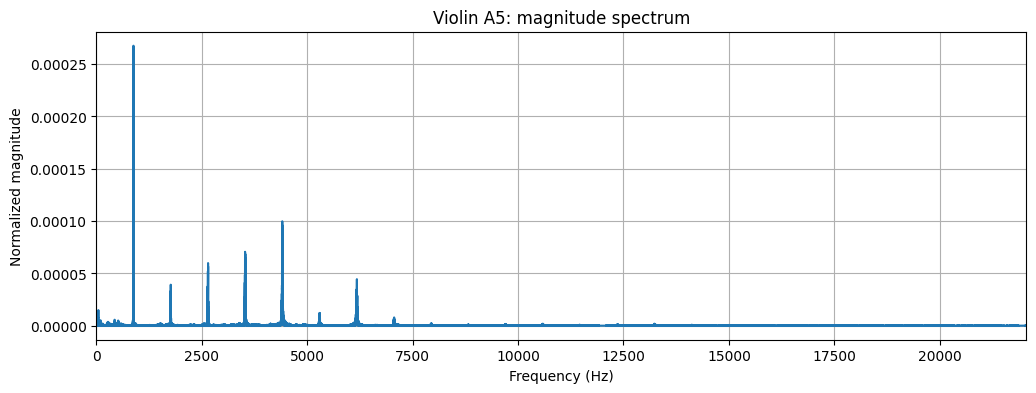

In [7]:
# Compute FFT
Y = np.fft.rfft(y)
freqs = np.fft.rfftfreq(len(y), d=1/sr)
magnitude = np.abs(Y) / len(y)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(freqs, magnitude)
plt.xlim(0, sr / 2)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Normalized magnitude")
plt.title("Violin A5: magnitude spectrum")
plt.grid(True)
plt.show()

### **1.3 Identify and plot harmonics** [0.5 score]
- Find the **fundamental frequency** (f₀) corresponding to the pitch (e.g., A4 = 440 Hz).
- Calculate harmonics f₀, 2f₀, 3f₀, ..., up to 5000 Hz.
- Plot harmonics as vertical dashed lines and annotate them (e.g., "1st harmonic", "2nd harmonic").

> 📌 **Hint**: You can get theoretical f₀ from `librosa.note_to_hz('A4')`.

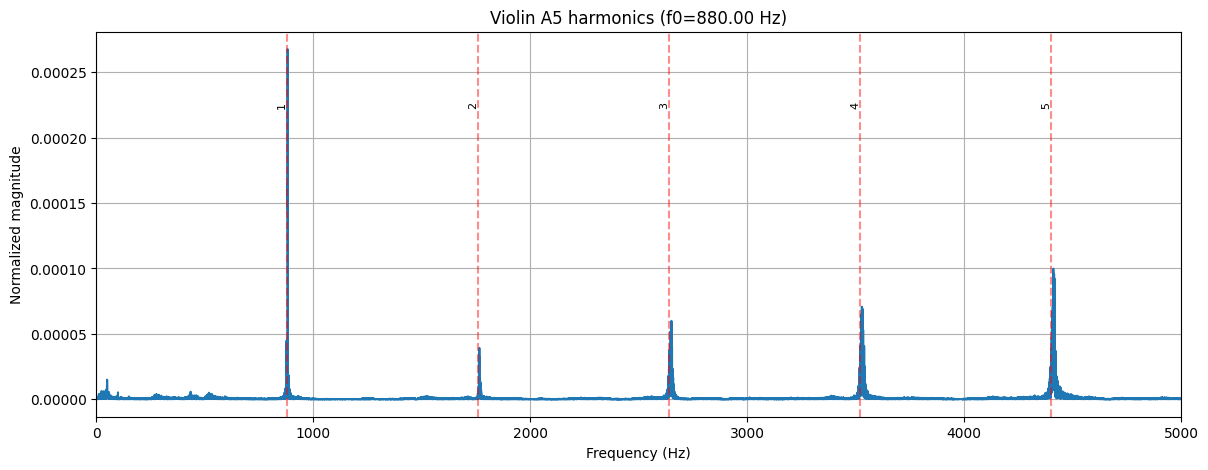

In [8]:
f0 = librosa.note_to_hz('A5')
max_freq = 5000
harmonics = []
n = 1
while n * f0 <= max_freq:
    harmonics.append(n * f0)
    n += 1

# Plot with harmonics marked
plt.figure(figsize=(14, 5))
plt.plot(freqs, magnitude, label="Magnitude spectrum")
for i, h in enumerate(harmonics, start=1):
    plt.axvline(h, color="red", linestyle="--", alpha=0.45)
    if i <= 5:
        plt.text(h, magnitude.max()*0.85, f"{i}", rotation=90,
                 ha="right", va="top", fontsize=8)
plt.xlim(0, max_freq)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Normalized magnitude")
plt.title(f"Violin A5 harmonics (f0={f0:.2f} Hz)")
plt.grid(True)
plt.show()

### **1.4 Answer: What is the fundamental frequency? What are the amplitudes of the 2nd, 3rd, and 5th harmonics?** [1 score]
- What is the fundamental frequency?
- What are the amplitudes of the 2nd, 3rd, and 5th harmonics?
- Report numerical values (in Hz and amplitude).
- Is the strongest peak always at f₀?

In [9]:
# Find the maximum spectral magnitude in a narrow neighborhood of each harmonic.
def get_harmonic_amplitude(freq, spectrum, freqs):
    bandwidth = max(10.0, freq * 0.015)
    mask = np.abs(freqs - freq) <= bandwidth
    if not np.any(mask):
        return 0.0
    return float(np.max(spectrum[mask]))

fundamental_amp = get_harmonic_amplitude(f0, magnitude, freqs)
second_harm_amp = get_harmonic_amplitude(2*f0, magnitude, freqs)
third_harm_amp = get_harmonic_amplitude(3*f0, magnitude, freqs)
fifth_harm_amp = get_harmonic_amplitude(5*f0, magnitude, freqs)

print(f"Fundamental frequency (f0): {f0:.1f} Hz")
print(f"Fundamental amplitude: {fundamental_amp:.4f}")
print(f"2nd harmonic amplitude: {second_harm_amp:.4f}")
print(f"3rd harmonic amplitude: {third_harm_amp:.4f}")
print(f"5th harmonic amplitude: {fifth_harm_amp:.4f}")

Fundamental frequency (f0): 880.0 Hz
Fundamental amplitude: 0.0003
2nd harmonic amplitude: 0.0000
3rd harmonic amplitude: 0.0001
5th harmonic amplitude: 0.0001


### **1.5 Repeat for another instruments playing the same pitch** [1 score]
- Choose a different instruments.
- Repeat steps 1.1–1.3.
- **Compare** the two spectra (Violin and another instrument):
  - Are the harmonic amplitudes similar?
  - Which instrument has more high-frequency harmonics?
  - How does this relate to timbre?

In [10]:
!gdown 19RVoksj40dds4lfSiha17HuTLYCFvwCs # Cello: Vc-ord-A5-pp-1c-N.wav
!gdown 1gVMlgMg9wGyPGRIbu7e_Q67JfzU0Rn1E # Accordion: Acc-ord-A5-pp-N-N.wav
!gdown 1gstlGhDe7SYEMpHQV6N50zb8TPByL2gI # Flute: Fl-ord-A5-pp-N-N.wav

Downloading...
From: https://drive.google.com/uc?id=19RVoksj40dds4lfSiha17HuTLYCFvwCs
To: /content/Vc-ord-A5-pp-1c-N.wav
100% 651k/651k [00:00<00:00, 121MB/s]
Downloading...
From: https://drive.google.com/uc?id=1gVMlgMg9wGyPGRIbu7e_Q67JfzU0Rn1E
To: /content/Acc-ord-A5-pp-N-N.wav
100% 600k/600k [00:00<00:00, 117MB/s]
Downloading...
From: https://drive.google.com/uc?id=1gstlGhDe7SYEMpHQV6N50zb8TPByL2gI
To: /content/Fl-ord-A5-pp-N-N.wav
100% 535k/535k [00:00<00:00, 122MB/s]


In [11]:
database = {'Accordion': 'Acc-ord-A5-pp-N-N.wav',
            'Cello': 'Vc-ord-A5-pp-1c-N.wav',
            'Flute': 'Fl-ord-A5-pp-N-N.wav',
            'Violin': 'Vn-ord-A5-pp-1c-N.wav'}

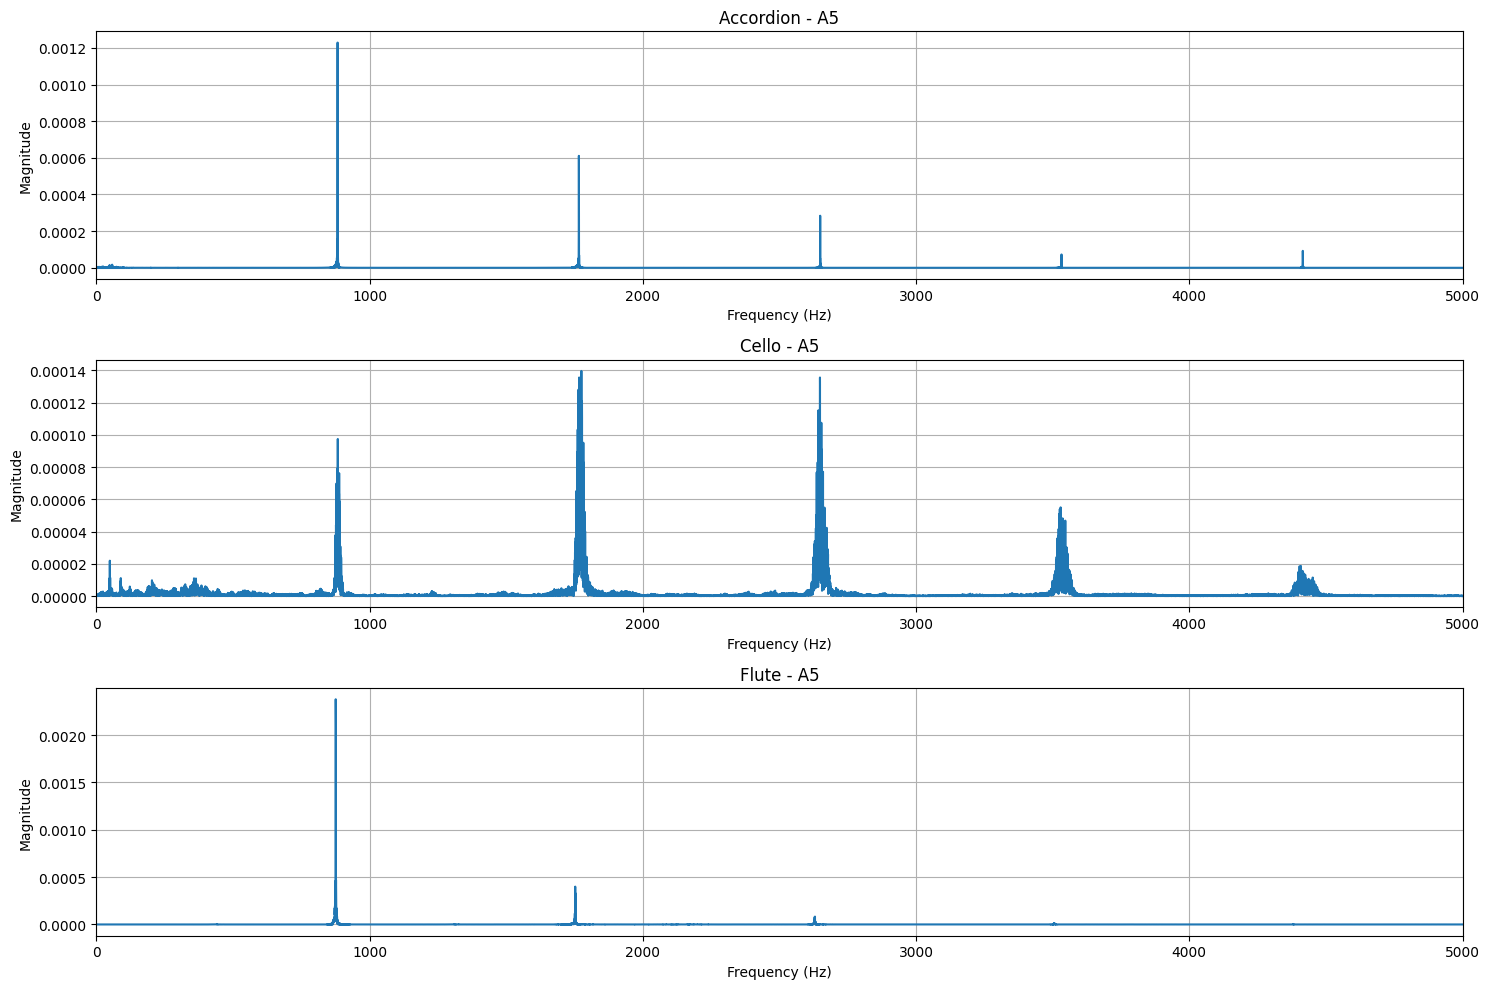

In [12]:
instruments_to_compare = ['Accordion', 'Cello', 'Flute']
plt.figure(figsize=(15, 10))

for i, inst in enumerate(instruments_to_compare):
    path_to_wav = database[inst]
    y_inst, sr_inst = librosa.load(path_to_wav, sr=None)

    Y_inst = np.fft.rfft(y_inst)
    freqs_inst = np.fft.rfftfreq(len(y_inst), d=1/sr_inst)
    magnitude_inst = np.abs(Y_inst) / len(y_inst)

    plt.subplot(3, 1, i+1)
    plt.plot(freqs_inst, magnitude_inst)
    plt.xlim(0, 5000)
    plt.title(f'{inst.capitalize()} - A5')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)

plt.tight_layout()
plt.show()

### **1.6 Count significant harmonics** [1 score]
- Define a "significant harmonic" as one with amplitude > 10% of the max amplitude.
- For **Flute** and **Violin** (same pitch), count how many significant harmonics each has.
- Which instrument is "brighter"? Why?

In [13]:
def count_significant_harmonics(magnitude, freqs, f0, max_freq=5000, threshold_ratio=0.1):
    peak_threshold = threshold_ratio * np.max(magnitude)
    harmonics = []
    n = 1
    while n * f0 <= max_freq:
        amp = get_harmonic_amplitude(n * f0, magnitude, freqs)
        if amp > peak_threshold:
            harmonics.append((n, n * f0, amp))
        n += 1
    return len(harmonics), harmonics

# Compare Flute and violin
for inst in ['Flute', 'Violin']:
    path_to_wav = database[inst]
    y_inst, sr_inst = librosa.load(path_to_wav, sr=None)
    Y_inst = np.fft.rfft(y_inst)
    freqs_inst = np.fft.rfftfreq(len(y_inst), d=1/sr_inst)
    magnitude_inst = np.abs(Y_inst) / len(y_inst)

    count, harm_list = count_significant_harmonics(magnitude_inst, freqs_inst, f0)
    print(f"{inst.capitalize()}: {count} significant harmonics")
    print("Harmonic numbers:", [h[0] for h in harm_list])

Flute: 2 significant harmonics
Harmonic numbers: [1, 2]
Violin: 5 significant harmonics
Harmonic numbers: [1, 2, 3, 4, 5]


### **1.7. Simple Instrument Classification** [2 score]
- Select 3 instruments, each with 10 examples of the **same pitch** (e.g., A4).
- **Approach A**: Use raw audio waveforms (flattened) as features → train a Random Forest.
- **Approach B**: Use magnitude spectrum (first 1024 bins) as features → train same model.
- Compare accuracy on a test set.
- **Question**: Why does Approach B perform better?

> 🛠️ Use `sklearn.tree.RandomForestClassifier` and `train_test_split`.

First, download dataset.

In [14]:
!gdown --folder 1wMa4fDtWRtO-YAz-gY5Jdrl94GQZUwmO # download dataset

Retrieving folder contents
Retrieving folder 1iRMqnkH7_GFqdt4EQ-XNIvzrGpWEY7BJ Strings
Retrieving folder 1AYkFHBz5tmYeC_TXouqyrXHobvwlpmAg Violin
Retrieving folder 1MczsLg3MRdzt5-xJ6nvqxRAaEjUOCZ27 ordinario
Processing file 14EjlXc_tdIJYbyMysUiC4hLRYfjV3HAv Vn-ord-A5-ff-1c-N.wav
Processing file 1JVag7kvYhGLW5ZVLJ-mxDXZ-F1wPLA02 Vn-ord-A5-ff-2c-N.wav
Processing file 1vQl-LIBK1JakJoDdR7sv-jdidz_COToj Vn-ord-A5-ff-3c-N.wav
Processing file 1z85hpjJPvFXp1V5cD3pD88-8aD0Zn1a1 Vn-ord-A5-mf-1c-N.wav
Processing file 1jptv0jF2rwILfPXwo8DdtWK533p4OK13 Vn-ord-A5-mf-2c-N.wav
Processing file 1jRAo5qm2zIsqf0sGzowAzb4emktEopWz Vn-ord-A5-mf-3c-N.wav
Processing file 1kbocn0_6etfg_LLBX4SAESNwBAqxOyWi Vn-ord-A5-pp-1c-N.wav
Processing file 1p5Xs5rXQX6e_wAtLXOixcB7C6hB9aEgI Vn-ord-A5-pp-2c-N.wav
Processing file 1E2xvckcJZSu68_yyJM_xl8aWsudNRZ5n Vn-ord-A5-pp-3c-N.wav
Retrieving folder 1bgPVnul9gXyQ1GK2YJDCY3JzKkcVlyRi Violoncello
Retrieving folder 1CjCmGKunsLKLLxfB8mbvZP7--YepiIH0 ordinario
Processing file 1q

In [17]:
# Read TinySOL metadata. The downloaded folder is expected in the current directory
# (in Colab: /content/TinySOL_short).
import os
csv_candidates = [
    "/content/TinySOL_short/TinySOL_short.csv",
    "TinySOL_short/TinySOL_short.csv",
    "TinySOL_short.csv"
]
csv_path = next((p for p in csv_candidates if os.path.exists(p)), None)
if csv_path is None:
    raise FileNotFoundError("TinySOL_short.csv not found. Run the dataset download cell first.")
df = pd.read_csv(csv_path)
print(df.shape)
print(df.columns.tolist())

(15, 14)
['Path', 'Fold', 'Family', 'Instrument (abbr.)', 'Instrument (in full)', 'Technique (abbr.)', 'Technique (in full)', 'Pitch', 'Pitch ID', 'Dynamics', 'Dynamics ID', 'Instance ID', 'String ID (if applicable)', 'Needed digital retuning']


In [18]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import os

# Select 10 recordings per instrument at pitch A5.
instruments_class = ['Violin', 'Flute', 'Cello']
subset = df[(df['Instrument (in full)'].isin(instruments_class)) &
            (df['Pitch'] == 'A5')].copy()
path_col = next((c for c in ['Path', 'path', ' audio_path', 'File', 'Filename', 'file']
                 if c in subset.columns), None)
if path_col is None:
    # TinySOL releases commonly store paths in the "Path" column.
    raise KeyError("Could not identify the audio path column in TinySOL metadata: " +
                   str(subset.columns.tolist()))

X_wave, X_spec, y_labels = [], [], []
target_len = 22050  # one second at 22.05 kHz
for instrument in instruments_class:
    rows = subset[subset['Instrument (in full)'] == instrument].head(10)
    if len(rows) < 2:
        raise ValueError(f"Not enough A5 examples for {instrument}: {len(rows)}")
    for _, row in rows.iterrows():
        audio_file = str(row[path_col])
        candidates = [audio_file, os.path.join(os.path.dirname(csv_path), audio_file),
                      os.path.join("/content/TinySOL_short", audio_file)]
        audio_file = next((q for q in candidates if os.path.exists(q)), candidates[0])
        signal, _ = librosa.load(audio_file, sr=22050)
        if len(signal) < target_len:
            signal = np.pad(signal, (0, target_len-len(signal)))
        else:
            signal = signal[:target_len]
        X_wave.append(signal)
        spectrum = np.abs(np.fft.rfft(signal))
        X_spec.append(spectrum[:1024])
        y_labels.append(instrument)

X_wave = np.asarray(X_wave)
X_spec = np.asarray(X_spec)
y_labels = np.asarray(y_labels)

# Use identical stratified train/test indices for a fair comparison.
indices = np.arange(len(y_labels))
train_idx, test_idx = train_test_split(
    indices, test_size=0.3, random_state=42, stratify=y_labels
)

clf_wave = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_spec = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
clf_wave.fit(X_wave[train_idx], y_labels[train_idx])
clf_spec.fit(X_spec[train_idx], y_labels[train_idx])

acc_wave = accuracy_score(y_labels[test_idx], clf_wave.predict(X_wave[test_idx]))
acc_spec = accuracy_score(y_labels[test_idx], clf_spec.predict(X_spec[test_idx]))

print(f"Accuracy with raw waveforms: {acc_wave:.3f}")
print(f"Accuracy with spectra: {acc_spec:.3f}")

Accuracy with raw waveforms: 0.600
Accuracy with spectra: 0.400


**Answer**: Спектр обычно работает лучше, потому что он описывает распределение энергии по частотам — непосредственно связанные с тембром гармоники. Сырые отсчёты сильно зависят от фазы, точного временного сдвига и длительности записи: даже два звучания одного инструмента могут иметь заметно разные массивы отсчётов. Спектральные признаки менее чувствительны к фазе и лучше отражают устойчивые различия тембра. Фактическая точность зависит от выбранных записей и разбиения train/test.

# **Task 2: Windowing in STFT – Why Not Rectangular?** [10 score]

### **Goal**: Understand spectral leakage and why smooth windows (e.g., Hann) are preferred.

### **2.1 Load a pure sine wave** [0.5 score]
- Generate a 440 Hz sine wave, 1 second long, at 22050 Hz sampling rate.
- Plot the waveform.

$$y = \sin(2 \pi ft)$$

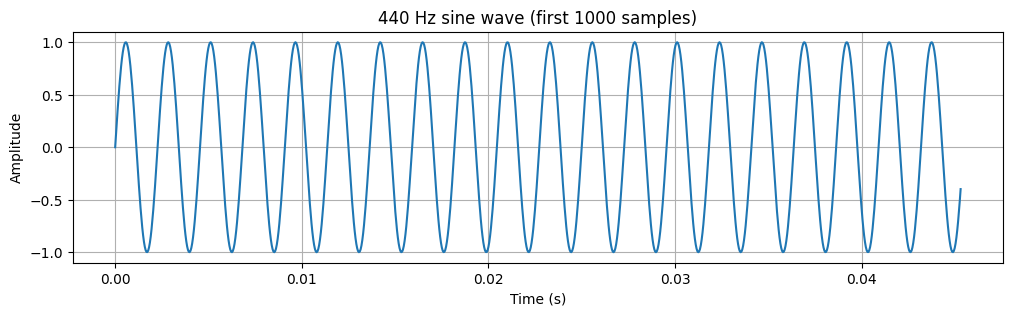

In [19]:
sr = 22050
duration = 1.0
t = np.linspace(0, duration, int(sr * duration), endpoint=False)
f0 = 440
sine_wave = np.sin(2 * np.pi * f0 * t)

plt.figure(figsize=(12, 3))
plt.plot(t[:1000], sine_wave[:1000])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("440 Hz sine wave (first 1000 samples)")
plt.grid(True)
plt.show()

### **2.2 Compute STFT with rectangular window** [1 score]
- Use `scipy.signal.stft` with `window='boxcar'` (rectangular), `nperseg=1024`, `noverlap=512`.
- Plot the spectrogram (use `plt.pcolormesh` with dB scale).

> 💡 Convert to dB: `10 * np.log10(np.abs(Zxx) + 1e-10)`

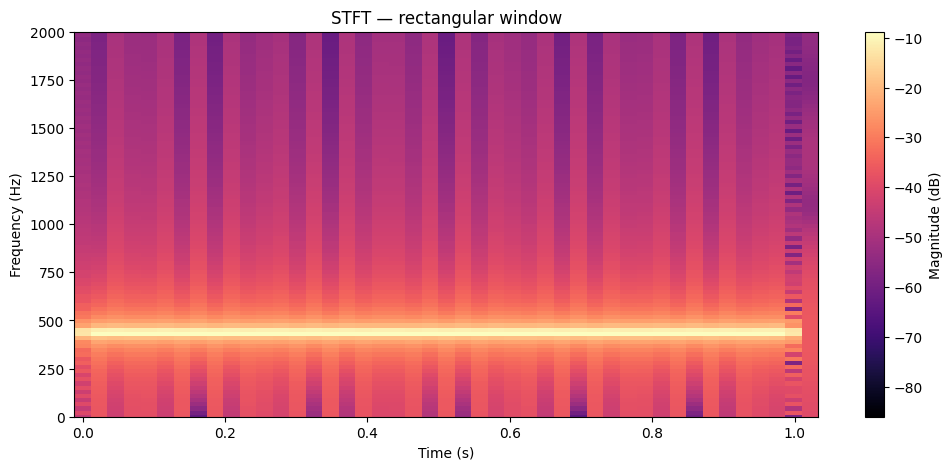

In [20]:
# Compute STFT with rectangular window
f_rect, t_rect, Z_rect = stft(
    sine_wave, fs=sr, window='boxcar', nperseg=1024, noverlap=512
)

# Plot spectrogram
plt.figure(figsize=(12, 5))
plt.pcolormesh(t_rect, f_rect, 20*np.log10(np.abs(Z_rect)+1e-10),
               shading='auto', cmap='magma')
plt.ylim(0, 2000)
plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("STFT — rectangular window")
plt.show()

### **2.3 Compute STFT with Hann window** [1 score]
- Repeat with `window='hann'`.
- Plot the spectrogram.

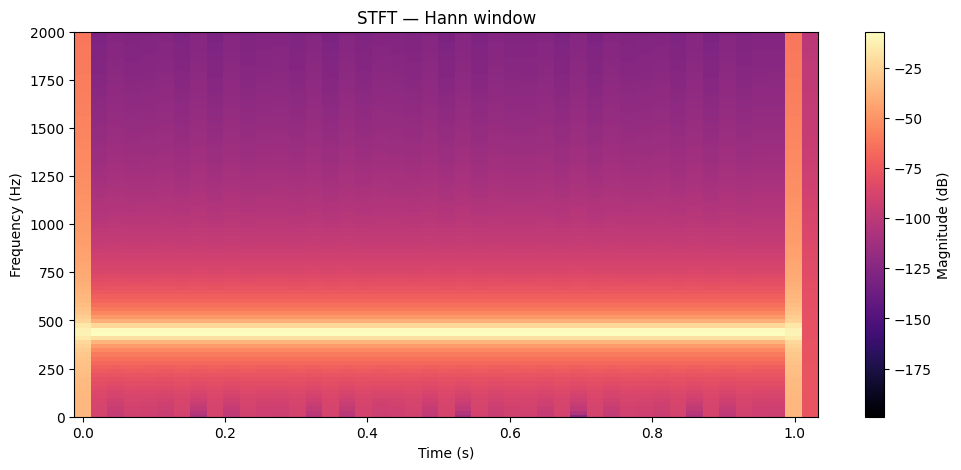

In [21]:
# Compute STFT with hann window
f_hann, t_hann, Z_hann = stft(
    sine_wave, fs=sr, window='hann', nperseg=1024, noverlap=512
)

# Plot spectrogram
plt.figure(figsize=(12, 5))
plt.pcolormesh(t_hann, f_hann, 20*np.log10(np.abs(Z_hann)+1e-10),
               shading='auto', cmap='magma')
plt.ylim(0, 2000)
plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("STFT — Hann window")
plt.show()

### **2.4 Compare the two spectrograms** [1.5 score]
- **Question**: In the rectangular case, do you see energy at frequencies **other than 440 Hz**? [0.5 score]
- **Question**: Is the main lobe wider or narrower with Hann? [0.5 score]
- **Question**: Which window shows cleaner, more focused energy at 440 Hz? [0.5 score]

Answers to questions:
Да. Прямоугольное окно обрезает сигнал резкими границами, поэтому энергия тона распределяется и по соседним частотным бинам — возникает spectral leakage.
У окна Hann главный лепесток шире, чем у прямоугольного окна, зато боковые лепестки значительно ниже.
Hann обычно даёт более чистую картину с меньшими боковыми составляющими; прямоугольное окно имеет более узкий главный лепесток, но сильнее протекает по частоте.

### **2.5 Try a signal with two close frequencies** [2 score]
- Generate two sine waves: 440 Hz and 460 Hz.
- Repeat 2.2 and 2.3.
- **Question**: Can you distinguish the two tones with rectangular window? With Hann?


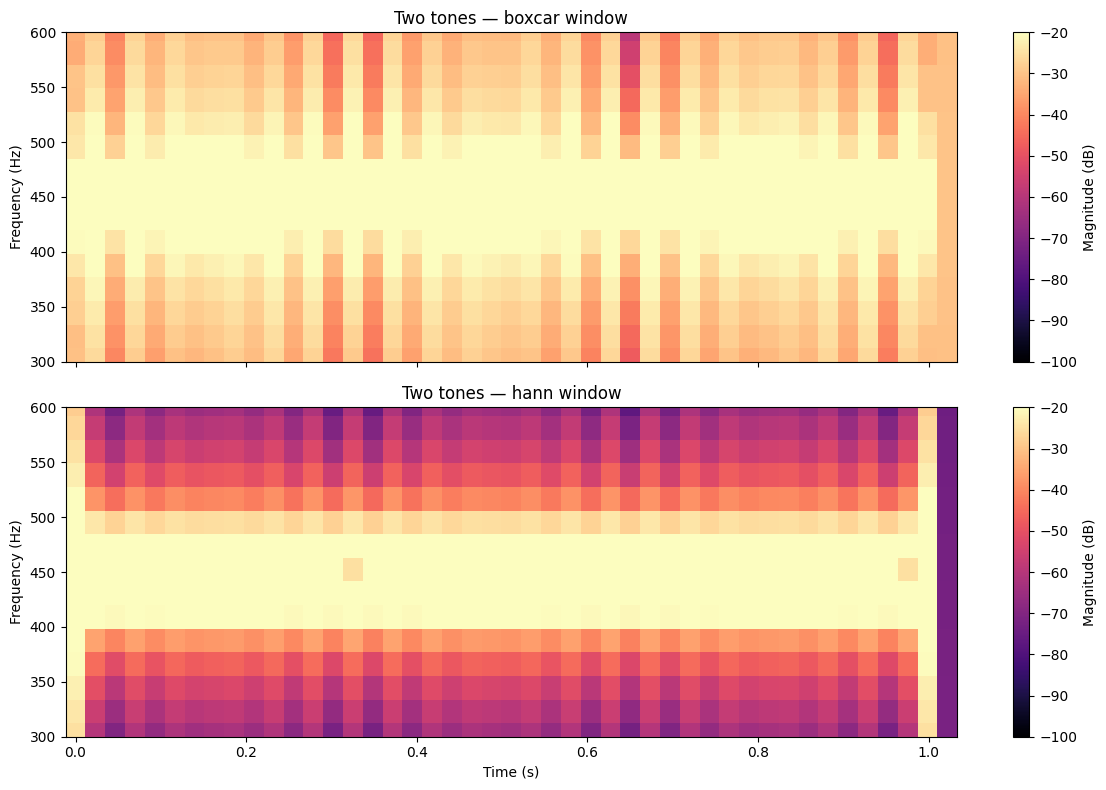

In [22]:
# Two close frequencies: 440 Hz and 460 Hz
two_tone = np.sin(2*np.pi*440*t) + np.sin(2*np.pi*460*t)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, window_name in zip(axes, ['boxcar', 'hann']):
    f, tt, Z = stft(two_tone, fs=sr, window=window_name,
                    nperseg=1024, noverlap=512)
    mesh = ax.pcolormesh(tt, f, 20*np.log10(np.abs(Z)+1e-10),
                         shading='auto', vmin=-100, vmax=-20, cmap='magma')
    ax.set_ylim(300, 600)
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(f"Two tones — {window_name} window")
    fig.colorbar(mesh, ax=ax, label="Magnitude (dB)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

**Answer**: При nperseg=1024 частотный шаг равен примерно 21.5 Гц, то есть расстояние между тонами (20 Гц) меньше одного бина. Поэтому надёжно разделить 440 и 460 Гц трудно с обоими окнами. У прямоугольного окна главный лепесток уже, что может помочь различению близких тонов, но боковые лепестки выше; у Hann утечка меньше, однако главный лепесток шире. Увеличение nperseg улучшило бы частотное разрешение.

### **2.6 Analyze a real instrument note** [1 score]
- Load a flute note (A5).
- Compute spectrograms with rectangular and Hann windows.
- **Question**: Does rectangular window create "smearing" or artificial frequencies? [0.5 score]
- **Question**: Which spectrogram better reflects the true harmonic structure? [0.5 score]

In [23]:
# Load flute note A5
row = df[(df['Instrument (in full)'] == "Flute") & (df['Pitch'] == 'A5')].iloc[0]
audio_file = str(row[path_col])
candidates = [audio_file, os.path.join(os.path.dirname(csv_path), audio_file),
              os.path.join("/content/TinySOL_short", audio_file)]
audio_file = next((q for q in candidates if os.path.exists(q)), candidates[0])
y_inst, sr_inst = librosa.load(audio_file, sr=None)

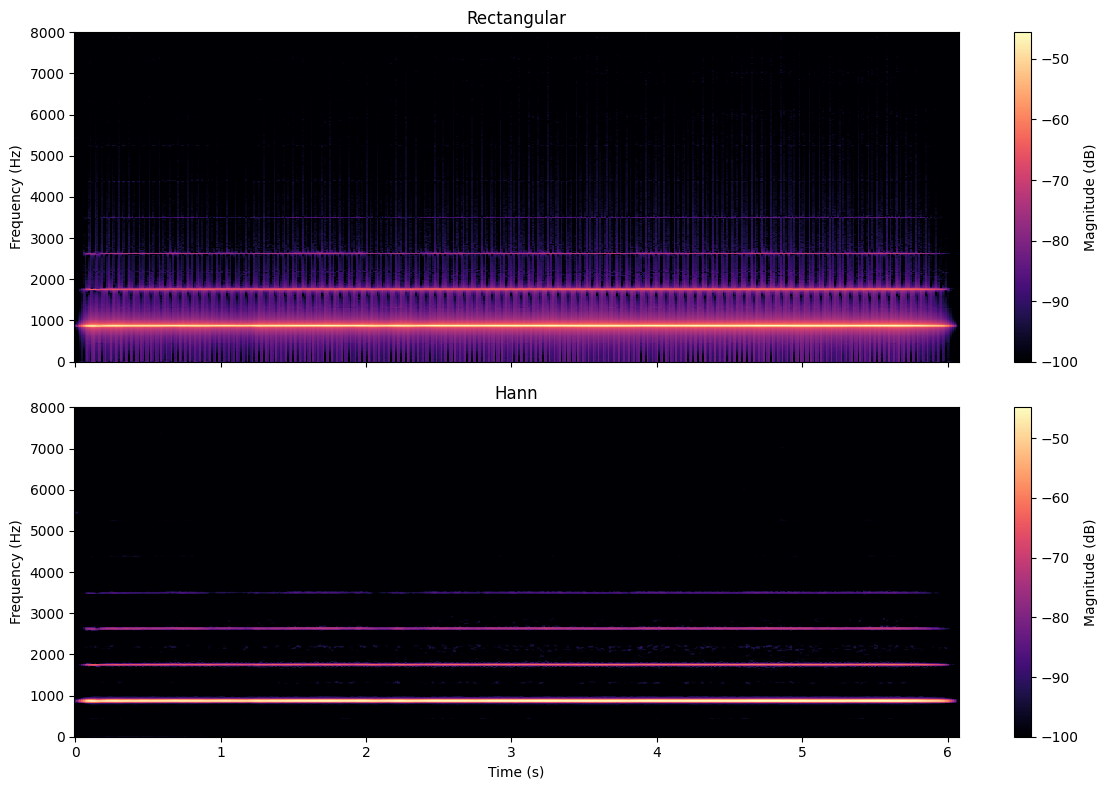

In [24]:
# Compute STFT with rectangular and hann window
nperseg = 2048
noverlap = 1536
f_r, tt_r, Z_r = stft(y_inst, fs=sr_inst, window='boxcar',
                      nperseg=nperseg, noverlap=noverlap)
f_h, tt_h, Z_h = stft(y_inst, fs=sr_inst, window='hann',
                      nperseg=nperseg, noverlap=noverlap)

# Plot spectrograms
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, sharey=True)
for ax, f, tt, Z, name in [
    (axes[0], f_r, tt_r, Z_r, 'Rectangular'),
    (axes[1], f_h, tt_h, Z_h, 'Hann')
]:
    mesh = ax.pcolormesh(tt, f, 20*np.log10(np.abs(Z)+1e-10),
                         shading='auto', vmin=-100, cmap='magma')
    ax.set_ylim(0, 8000)
    ax.set_ylabel('Frequency (Hz)')
    ax.set_title(name)
    fig.colorbar(mesh, ax=ax, label='Magnitude (dB)')
axes[-1].set_xlabel('Time (s)')
plt.tight_layout()
plt.show()

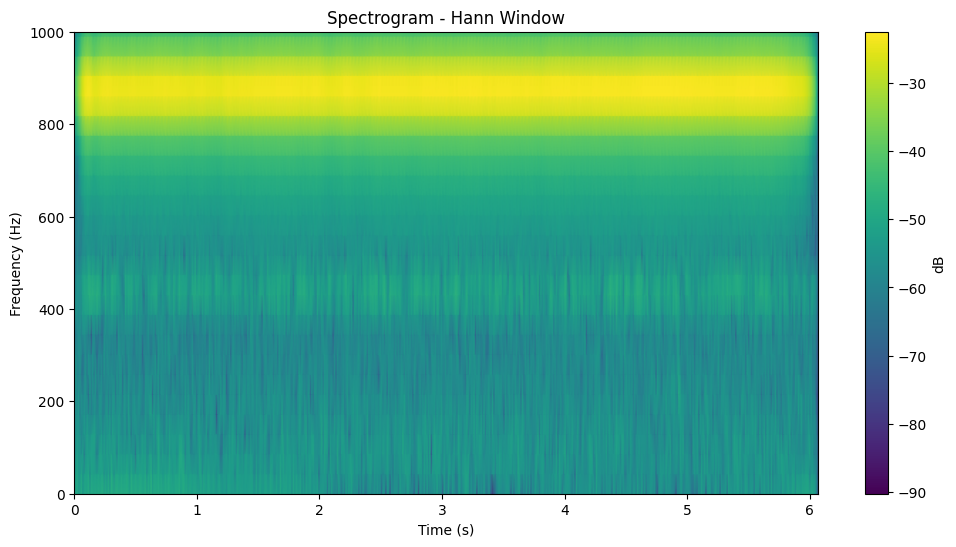

**Answer**: Прямоугольное окно может добавлять боковые спектральные составляющие вокруг гармоник из-за резкого обрезания фрагмента сигнала. Окно Hann подавляет эти боковые лепестки, поэтому гармоническая структура обычно выглядит чище. При этом главный лепесток Hann шире, так что близкие гармоники могут сливаться сильнее.

### **2.7 Conclusion** [3 score]
- Write 3–4 sentences explaining:
  - What is **spectral leakage**?
  - Why does rectangular window cause it?
  - Why is a smooth (bell-shaped) window better for audio analysis?

**Answer**: Спектральная утечка — это распределение энергии одной спектральной компоненты по соседним частотам вместо концентрации в одном бине. Она возникает потому, что конечный фрагмент сигнала умножается на окно, а прямоугольное окно имеет резкие края и высокие боковые лепестки в частотной области. Плавное окно Hann постепенно уменьшает сигнал к краям фрагмента и подавляет боковые лепестки. Поэтому оно обычно лучше подходит для анализа аудио, когда важно уменьшить ложную энергию на соседних частотах, хотя его главный лепесток шире.

# **Task 3: Implement Your Own Mel-Spectrogram Transform** [5 score]

### **Goal**: Understand how Mel-scale warping works by implementing it manually.

### **3.1 Load an audio file** [0.5 score]
- Pick any `.wav` from the dataset.
- Load with `librosa.load(..., sr=22050)`.

In [25]:
# Load audio
sample = df.iloc[0]
audio_file = str(sample[path_col])
candidates = [audio_file, os.path.join(os.path.dirname(csv_path), audio_file),
              os.path.join("/content/TinySOL_short", audio_file)]
audio_file = next((q for q in candidates if os.path.exists(q)), candidates[0])
y, sr = librosa.load(audio_file, sr=22050)

### **3.2 Compute STFT** [0.5 score]
- Use `librosa.stft` with `n_fft=2048`, `hop_length=512`, `window='hann'`.
- Compute power spectrogram: `S = np.abs(stft_result) ** 2`.

In [26]:
# Compute STFT and power spectrogram
n_fft = 2048
hop_length = 512
stft_result = librosa.stft(y, n_fft=n_fft, hop_length=hop_length, window='hann')
S = np.abs(stft_result) ** 2
print("Power spectrogram shape:", S.shape)

Power spectrogram shape: (1025, 319)


### **3.3 Create Mel filterbank manually** [2 score]
- Number of Mel bands: `n_mels = 128`.
- Frequency range: 0 to `sr/2`.
- Steps:
  1. Convert Hz to Mel: `mel = 2595 * np.log10(1 + f / 700)`
  2. Create `n_mels + 2` equally spaced points in Mel scale.
  3. Convert back to Hz.
  4. Build triangular filters (each filter overlaps with neighbors).
- Output: a matrix `mel_basis` of shape `(n_mels, n_fft//2 + 1)`.

> 📚 Reference: [Librosa mel filterbank docs](https://librosa.org/doc/main/generated/librosa.filters.mel.html)

In [27]:
def hz_to_mel(frequencies):
    """Convert Hz to Mel scale (Slaney-independent HTK formula)."""
    frequencies = np.asarray(frequencies, dtype=float)
    return 2595.0 * np.log10(1.0 + frequencies / 700.0)

def mel_to_hz(mels):
    """Convert Mel to Hz scale."""
    mels = np.asarray(mels, dtype=float)
    return 700.0 * (10.0 ** (mels / 2595.0) - 1.0)

def create_mel_filterbank(sr, n_fft, n_mels=128, fmin=0.0, fmax=None):
    """Create triangular Mel filterbank manually."""
    if fmax is None:
        fmax = sr / 2

    n_freqs = n_fft // 2 + 1
    linear_freqs = np.fft.rfftfreq(n_fft, d=1/sr)

    min_mel = hz_to_mel(fmin)
    max_mel = hz_to_mel(fmax)
    mel_points = np.linspace(min_mel, max_mel, n_mels + 2)
    hz_points = mel_to_hz(mel_points)

    filterbank = np.zeros((n_mels, n_freqs), dtype=float)
    for m in range(n_mels):
        left, center, right = hz_points[m:m+3]
        rising = (linear_freqs - left) / max(center - left, 1e-12)
        falling = (right - linear_freqs) / max(right - center, 1e-12)
        filterbank[m] = np.maximum(0.0, np.minimum(rising, falling))

    return filterbank

# Create filterbank
mel_basis_manual = create_mel_filterbank(sr, n_fft, n_mels=128)

### **3.4 Apply filterbank to power spectrogram** [0.5 score]
- Compute: `mel_spec_manual = np.dot(mel_basis, S)`

In [28]:
# Apply manual filterbank
mel_spec_manual = np.dot(mel_basis_manual, S)

### **3.5 Compute Mel-spectrogram using librosa** [0.5 score]
- Use `librosa.feature.melspectrogram(y=audio, sr=sr, n_fft=2048, hop_length=512, n_mels=128)`

In [29]:
# Librosa version; use the same HTK Mel scale and unnormalized triangular filters
mel_spec_librosa = librosa.feature.melspectrogram(
    y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, window='hann',
    n_mels=128, fmin=0.0, fmax=sr/2, htk=True, norm=None, power=2.0
)

### **3.6 Compare and validate** [1 score]
- Use `np.allclose(mel_spec_manual, mel_spec_librosa, atol=1e-5)`
- If not close, debug your filterbank.
- Plot both Mel-spectrograms side by side (in dB scale).
- **Question**: Are they visually identical?

Manual and librosa implementations match: True
Maximum absolute difference: 4.467687002573939e-07


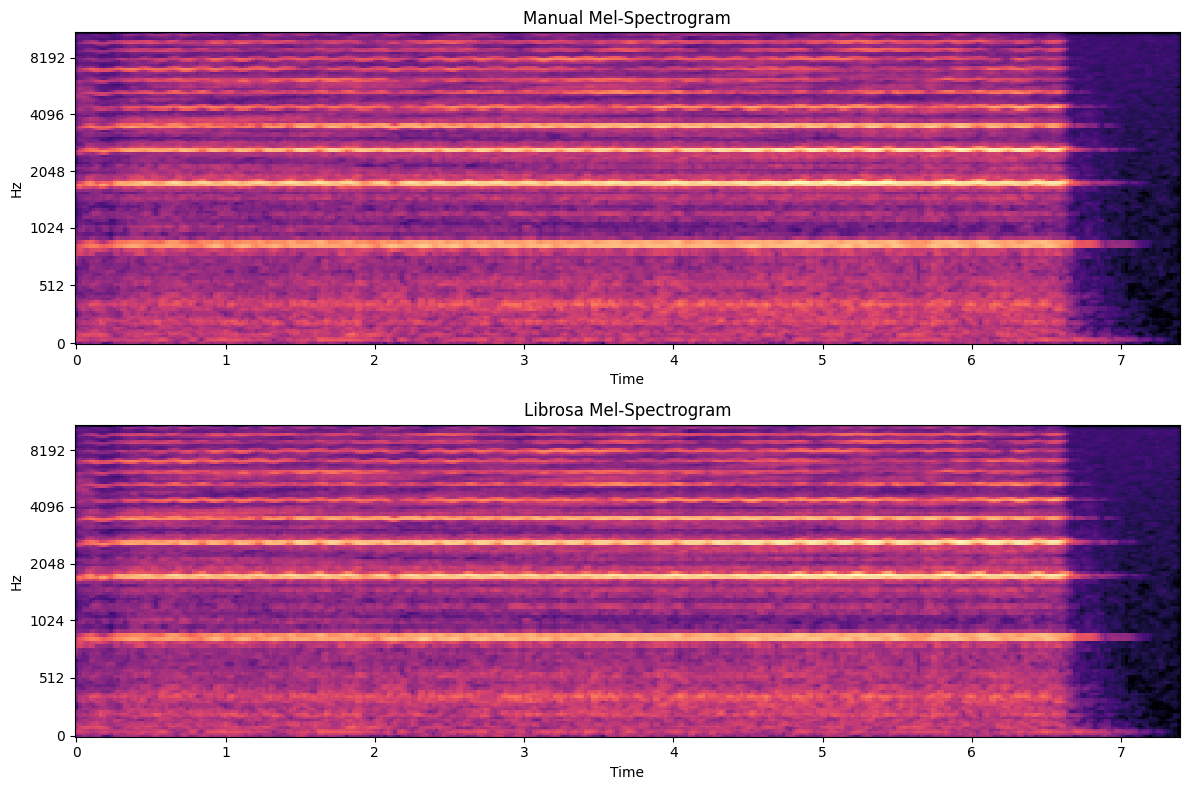

The plots should be visually almost identical when the same Mel scale and normalization are used.


In [30]:
# Compare
are_close = np.allclose(mel_spec_manual, mel_spec_librosa, atol=1e-5, rtol=1e-5)
print(f"Manual and librosa implementations match: {are_close}")
print("Maximum absolute difference:", np.max(np.abs(mel_spec_manual-mel_spec_librosa)))

# Plot comparison
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))
librosa.display.specshow(
    librosa.power_to_db(mel_spec_manual, ref=np.max),
    sr=sr, hop_length=hop_length, x_axis='time', y_axis='mel', htk=True, ax=ax1
)
ax1.set_title('Manual Mel-Spectrogram')
librosa.display.specshow(
    librosa.power_to_db(mel_spec_librosa, ref=np.max),
    sr=sr, hop_length=hop_length, x_axis='time', y_axis='mel', htk=True, ax=ax2
)
ax2.set_title('Librosa Mel-Spectrogram')
plt.tight_layout()
plt.show()

print("The plots should be visually almost identical when the same Mel scale and normalization are used.")

### **3.7 Bonus: Try with torchaudio**
- Repeat using `torchaudio.transforms.MelSpectrogram`.
- Compare with your implementation.

In [31]:
# !pip install torch torchaudio

In [32]:
import torchaudio
import torch
mel_transform = torchaudio.transforms.MelSpectrogram(
    sample_rate=sr, n_fft=n_fft, hop_length=hop_length, n_mels=128
)
mel_spec_torch = mel_transform(torch.tensor(y)).numpy()

# Note: torchaudio uses different scaling, so direct comparison needs care
